In [1]:
import numpy as np
import seaborn as sns
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

In [2]:
# Crear nuevo dataset no lineal (make_circles)
X_bin, y_bin = make_circles(n_samples=300, noise=0.2, factor=0.5, random_state=0)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_bin, y_bin, test_size=0.3, random_state=42)

In [3]:
# Grid para visualización
xxb, yyb = np.meshgrid(np.linspace(-1.5, 1.5, 500), np.linspace(-1.5, 1.5, 500))
gridb = np.c_[xxb.ravel(), yyb.ravel()]

In [4]:
# Nuevos modelos de clasificación
models_bin = [
    ("Modelo A: Regresión logística lineal (underfitting)", LogisticRegression()),
    ("Modelo B: SVM RBF C=1, gamma=1 (buen ajuste)", SVC(kernel='rbf', C=1, gamma=1)),
    ("Modelo C: SVM RBF C=100, gamma=100 (overfitting)", SVC(kernel='rbf', C=100, gamma=100)),
    ("Modelo D: Regresión logística con polinomios grado 3", Pipeline([
        ("poly", PolynomialFeatures(degree=3)),
        ("clf", LogisticRegression(max_iter=10000))
    ])),
    ("Modelo E: Regresión logística con polinomios grado 6 (riesgo de sobreajuste)", Pipeline([
        ("poly", PolynomialFeatures(degree=6)),
        ("clf", LogisticRegression(max_iter=10000))
    ])),
]

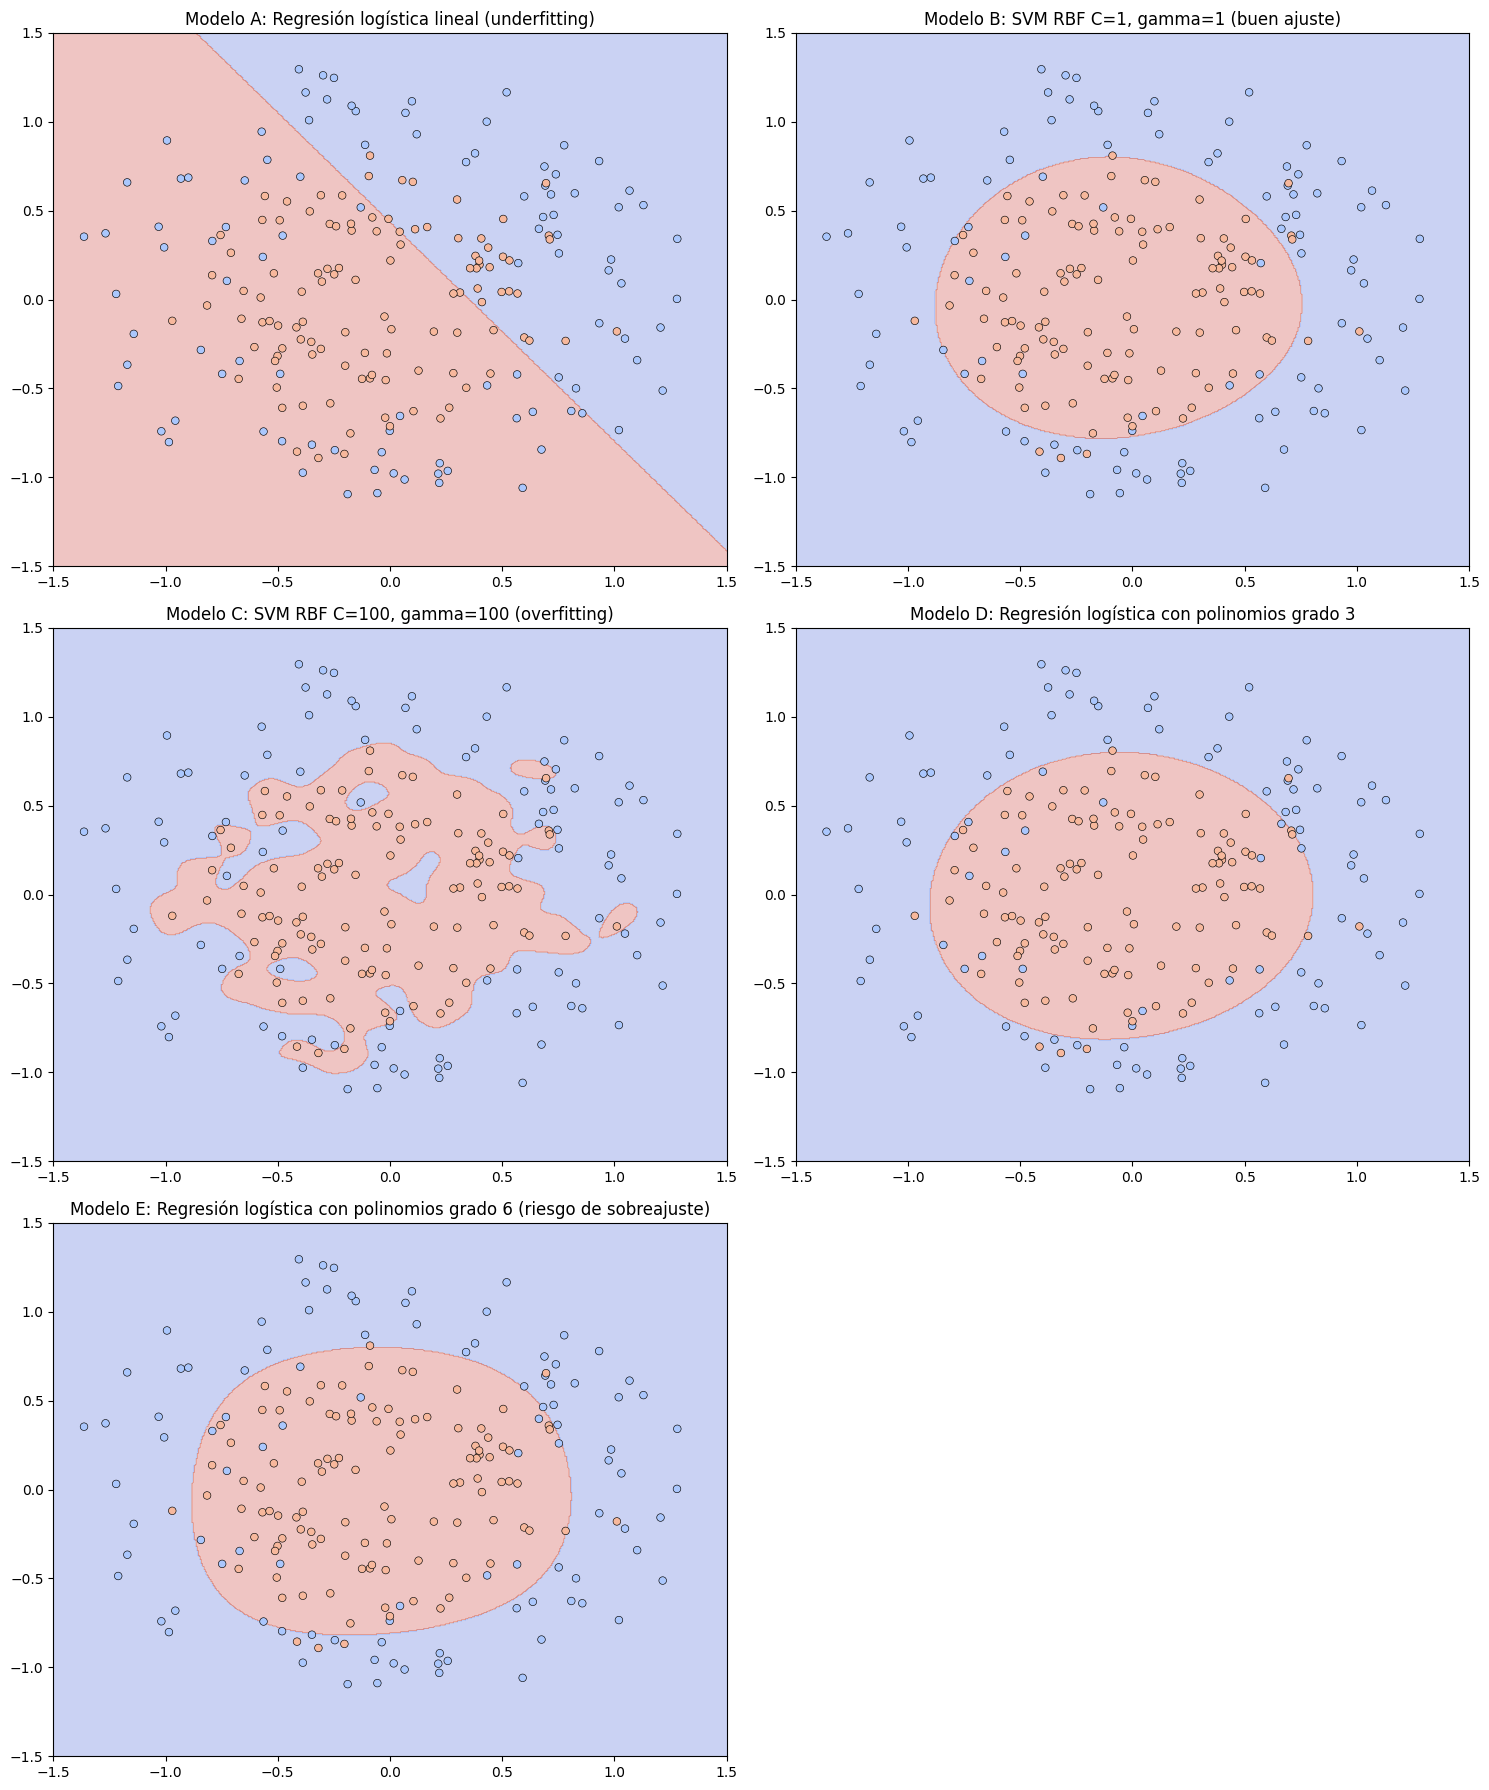

In [5]:
# Generar gráficos
fig, axs = plt.subplots(3, 2, figsize=(15, 18))
axs = axs.ravel()

for i, (title, model) in enumerate(models_bin):
    model.fit(Xb_train, yb_train)
    Zb = model.predict(gridb).reshape(xxb.shape)

    axs[i].contourf(xxb, yyb, Zb, alpha=0.3, cmap="coolwarm")
    sns.scatterplot(x=Xb_train[:, 0], y=Xb_train[:, 1], hue=yb_train, ax=axs[i],
                    palette="coolwarm", s=30, edgecolor="k", legend=False)
    axs[i].set_title(title)
    axs[i].set_xlim(-1.5, 1.5)
    axs[i].set_ylim(-1.5, 1.5)

# Ocultar último gráfico si queda vacío
axs[-1].axis("off")

plt.tight_layout()
plt.show()